# 01 - Preprocessing, Popularitas Conference, dan Transaksi (Task 1-3)

**Dataset**
- Sumber: DBLP computer science bibliography (https://dblp.org), dump XML `dblp.xml.gz` dari https://dblp.org/xml/. Kode ekstraksinya ada di `00_extraction.ipynb`.
- Tanggal pengambilan: 13-14 November 2026 (`mdate` terbaru di data: 2026-11-13).
- Cakupan: publikasi conference & workshop (`inproceedings`) tahun 2015-2025, 2.004.019 record sebelum preprocessing.
- Distribusi jenis publikasi (`distributionofpublicationtype.csv`) dari halaman statistik DBLP: https://dblp.org/statistics/distributionofpublicationtype.html

In [1]:
import os
import re
import unicodedata

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


DATA_DIR = '../data/raw'
PROCESSED_DIR = '../data/processed'

sns.set_theme(style="whitegrid")

## Task 1 - Data Understanding & Preprocessing

### 1.1 Eksplorasi dataset

Jenis publikasi di seluruh DBLP:

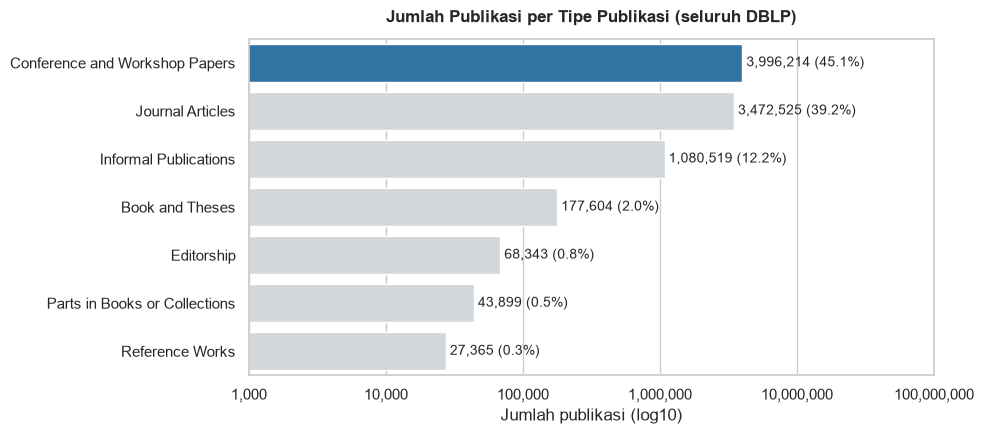

In [2]:
df_publication_distribution = pd.read_csv(f'{DATA_DIR}/distributionofpublicationtype.csv', delimiter=';')
df_publication_distribution = df_publication_distribution[['type', '#Publications']]

df_sorted = df_publication_distribution.sort_values(by='#Publications', ascending=False)
colors = ["#1f77b4" if t == "Conference and Workshop Papers" else "#cfd8dc" for t in df_sorted["type"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(df_sorted, x="#Publications", y="type", hue="type", palette=colors, legend=False, ax=ax)
ax.set_xscale("log")
ax.set_xlim(1000, 100000000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))

total = df_sorted['#Publications'].sum()
labels = [f" {val:,.0f} ({val/total*100:.1f}%)" for val in df_sorted['#Publications']]
for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], fontsize=10)

ax.set_xlabel("Jumlah publikasi (log10)")
ax.set_ylabel("")
ax.set_title("Jumlah Publikasi per Tipe Publikasi (seluruh DBLP)", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

Conference & workshop paper adalah jenis publikasi terbanyak di DBLP (3.996.214 atau 45,1%), di atas journal article (39,2%). Project ini hanya memakai jenis ini, untuk tahun 2015-2025.

In [3]:
df = pd.read_parquet(f'{DATA_DIR}/dblp_2015_2025_raw.parquet')

print("Jumlah record:", f"{len(df):,}")
print("Rentang tahun:", df['year'].min(), "-", df['year'].max())
df.info()

Jumlah record: 2,004,019
Rentang tahun: 2015 - 2025
<class 'pandas.DataFrame'>
RangeIndex: 2004019 entries, 0 to 2004018
Data columns (total 10 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   key       str   
 1   mdate     str   
 2   authors   object
 3   title     str   
 4   pages     str   
 5   year      int64 
 6   venue     str   
 7   doi       str   
 8   crossref  str   
 9   url       str   
dtypes: int64(1), object(1), str(8)
memory usage: 585.7+ MB


In [4]:
df.head()

,key,mdate,authors,title,pages,year,venue,doi,crossref,url
0,books/sp/15/KimLLRJPK15,2026-06-03,"[Kwang-Ho Kim, Donghyun Lee 0001, Minkyu Lim, ...",Performance Analysis of FFNN-Based Language Mo...,253-256,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_25,books/sp/2015LKJK,db/books/collections/LKJK2015.html#KimLLRJPK15
1,books/sp/15/ManuvinakurikeD15,2021-04-29,"[Ramesh R. Manuvinakurike, David DeVault]",Pair Me Up: A Web Framework for Crowd-Sourced ...,189-201,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_18,books/sp/2015LKJK,db/books/collections/LKJK2015.html#Manuvinakur...
2,books/sp/15/YoshinoK15,2021-04-29,"[Koichiro Yoshino, Tatsuya Kawahara]",News Navigation System Based on Proactive Dial...,15-25,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_2,books/sp/2015LKJK,db/books/collections/LKJK2015.html#YoshinoK15
3,books/sp/15/KwonLRHCKJOLKCPL15,2021-10-14,"[Oh-Woog Kwon, Ki-Young Lee, Yoon-Hyung Roh, J...",GenieTutor: A Computer-Assisted Second-Languag...,257-262,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_26,books/sp/2015LKJK,db/books/collections/LKJK2015.html#KwonLRHCKJO...
4,books/sp/15/HanKL15,2021-04-29,"[Sangdo Han, Yonghee Kim, Gary Geunbae Lee]",Micro-Counseling Dialog System Based on Semant...,63-72,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_6,books/sp/2015LKJK,db/books/collections/LKJK2015.html#HanKL15


Satu baris = satu paper. Ada 10 kolom: key (id paper di dblp), mdate (tanggal terakhir record diubah), authors, title, pages, year, venue (nama conference/workshop), doi, crossref, dan url.

Yang dipakai cuma authors, title, year, dan venue. Key dipakai buat urutan waktu hapus duplikat.

### 1.2 & 1.3 Preprocessing dan alasannya

**a. Memilih publikasi conference & workshop**

Sudah dilakukan saat ekstraksi dari dump XML DBLP: yang diambil hanya record `inproceedings` tahun 2015-2025. Hampir semua key berawalan `conf/`. Sisanya proceedings yang terbit di seri jurnal/buku (misalnya ENTCS), tetap termasuk paper conference.

In [5]:
df['key'].str.split('/').str[0].value_counts()

key
conf        2000856
journals       3123
books            40
Name: count, dtype: int64

**b. Missing values**

In [6]:
print("venue kosong  :", df['venue'].isna().sum())
print("authors kosong:", (df['authors'].str.len() == 0).sum())

# contoh judul yang authors-nya kosong
df.loc[df['authors'].str.len() == 0, 'title'].value_counts().head(5)

venue kosong  : 190


authors kosong: 2255


title
Front Matter, Table of Contents, Preface, Conference Organization.    349
Preface.                                                              143
Frontmatter.                                                          128
Conference Overview and Papers Program.                                36
Front Matter.                                                          31
Name: count, dtype: int64

In [7]:
df = df.dropna(subset=['venue'])
df = df[df['authors'].str.len() > 0]
print("Sisa:", f"{len(df):,}")

Sisa: 2,001,574


Record tanpa venue (190) tidak bisa dipetakan ke conference mana pun, jadi dibuang. Record tanpa author (2.255) isinya front matter seperti "Preface" atau "Front Matter", bukan paper, jadi juga dibuang. Kolom lain yang kosong (`pages`, `doi`, `crossref`) tidak dipakai, jadi dibiarkan.

**c. Duplikat**

In [8]:
# duplikat = judul, author, venue, dan tahun sama persis
df['authors_tuple'] = df['authors'].apply(tuple)
print("Duplikat:", df.duplicated(['title', 'authors_tuple', 'venue', 'year']).sum())

df = df.sort_values('key')
df = df.drop_duplicates(subset=['title', 'authors_tuple', 'venue', 'year'], keep='first')
print("Sisa:", f"{len(df):,}")

Duplikat: 615


Sisa: 2,000,959


Duplikat dicek dari kombinasi judul + author + venue + tahun. Kalau cuma pakai judul, judul umum seperti "Introduction" dari paper yang berbeda ikut terhapus. Data diurutkan dulu berdasarkan `key` supaya record yang disimpan selalu sama setiap run.

**d. Normalisasi nama author**

In [9]:
def normalize_authors(authors):
    result = []
    for name in authors:
        name = unicodedata.normalize('NFKC', name)
        name = name.lower().strip()
        name = re.sub(r'\s+', ' ', name)
        name = name.strip('.,;:')
        result.append(name)
    return result


df['authors_normalized'] = df['authors'].apply(normalize_authors)
df[['authors', 'authors_normalized']].head(3)

,authors,authors_normalized
11,"[Carina Corbin, Fabrizio Morbini, David R. Traum]","[carina corbin, fabrizio morbini, david r. traum]"
17,"[Luis Fernando D'Haro, Seokhwan Kim, Kheng Hui...","[luis fernando d'haro, seokhwan kim, kheng hui..."
12,"[Yannick Estève, Mohamed Bouallegue, Carole La...","[yannick estève, mohamed bouallegue, carole la..."


Penulisan nama yang sama bisa beda (huruf kapital, spasi ganda, karakter unicode), jadi nama dibuat NFKC, lowercase, dan spasi/tanda baca di ujungnya dirapikan. Angka di belakang nama (misalnya `wei wang 0001`) sengaja tidak dibuang, karena itu cara DBLP membedakan orang yang namanya sama.

**e. Normalisasi nama venue**

In [10]:
VENUE_MAPPING = {
    "nips": "neurips",
    "ieee bigdata": "ieee big data",
    "icce-tw": "icce-taiwan",
    "ismar-adjunct": "ismar adjunct",
    "fat*": "facct",
    "iccvw": "iccv workshops",
}


def normalize_venue(venue, merge_subtracks=True):
    # unicode, lowercase, buang tanda kutip
    venue = unicodedata.normalize('NFKC', venue).lower().strip()
    venue = venue.strip('"\'')

    # buang nomor volume/part, misalnya "(1)", "(27)", "(workshops 3)"
    venue = re.sub(r'\s*\((?:workshops?\s*)?\d+\)\s*$', '', venue)

    # buang tahun
    venue = re.sub(r'[-_\s]*\b(19|20)\d{2}\b[-_\s]*', ' ', venue)

    venue = re.sub(r'\s+', ' ', venue).strip()
    venue = VENUE_MAPPING.get(venue, venue)

    # gabungkan workshop/track ke conference induknya
    if merge_subtracks:
        # "(know@lod/codes)@eswc" -> "eswc"
        if '@' in venue:
            venue = venue.rsplit('@', 1)[-1].strip()

        venue = re.sub(r'\s*\(.*?\)\s*$', '', venue)
        venue = re.sub(
            r'\s+(workshops?|wkshps?|companion|adjunct|findings|posters?|demos?|extended abstracts|short papers|abstracts).*$',
            '',
            venue
        )
        venue = re.sub(r'\s+', ' ', venue).strip()
        venue = VENUE_MAPPING.get(venue, venue)

    return venue


df['venue_normalized'] = df['venue'].apply(normalize_venue)

print("Venue sebelum:", df['venue'].nunique())
print("Venue sesudah:", df['venue_normalized'].nunique())

Venue sebelum: 8903
Venue sesudah: 4478


In [11]:
# contoh variasi nama yang digabung jadi satu
for v in ['cvpr', 'hci', 'neurips']:
    print(f"{v}:", df.loc[df['venue_normalized'] == v, 'venue'].value_counts().head(5).to_dict())

cvpr: {'CVPR': 17435, 'CVPR Workshops': 5312, 'MedSAM@CVPR': 16, 'MedSegFM@CVPR': 13}
hci: {'HCI (27)': 507, 'HCI (2)': 491, 'HCI (1)': 485, 'HCI (18)': 470, 'HCI (15)': 468}
neurips: {'NeurIPS': 23358, 'NIPS': 1646, 'ML4H@NeurIPS': 196, 'NeurIPS (Competition and Demos)': 97, 'ViGIL@NeurIPS': 35}


Nama venue di DBLP ikut menyimpan nomor volume ("HCI (27)"), tahun, dan nama track/workshop ("CVPR Workshops"), jadi satu conference bisa punya banyak variasi nama. Nomor volume dan tahun dibuang, sinonim disamakan (`nips` -> `neurips`), dan workshop/track digabung ke conference induknya. Jumlah venue turun dari 8.903 jadi 4.478.

Asumsi: workshop dan track dihitung sebagai bagian dari conference induknya.

**f. Konsistensi tahun**

In [12]:
print("Tipe data:", df['year'].dtype)
print("Tahun di luar 2015-2025:", ((df['year'] < 2015) | (df['year'] > 2025)).sum())

Tipe data: int64
Tahun di luar 2015-2025: 0


Semua tahun sudah integer dan ada di rentang 2015-2025, jadi tidak ada yang perlu diubah.

Ringkasnya, dari 2.004.019 record dibuang 190 yang venue-nya kosong, 2.255 yang authors-nya kosong, dan 615 duplikat, jadi sisa 2.000.959 publikasi.

### 1.4 Statistik setelah preprocessing

In [13]:
print("Total publikasi   :", f"{len(df):,}")
print("Total author unik :", f"{df['authors_normalized'].explode().nunique():,}")
print("Total venue unik  :", f"{df['venue_normalized'].nunique():,}")

Total publikasi   : 2,000,959


Total author unik : 1,819,240
Total venue unik  : 4,478


**Distribusi publikasi per tahun**

In [14]:
df.groupby('year').size().reset_index(name='jumlah publikasi')

,year,jumlah publikasi
0,2015,161353
1,2016,162259
2,2017,168151
3,2018,176661
4,2019,188817
5,2020,172097
6,2021,178502
7,2022,178363
8,2023,201738
9,2024,213570


**Distribusi publikasi per conference**

In [15]:
pub_per_venue = df.groupby('venue_normalized').size().sort_values(ascending=False)

print("Venue dengan < 100 publikasi:", (pub_per_venue < 100).sum(), "dari", len(pub_per_venue))
print(f"Top 10 venue mencakup {pub_per_venue.head(10).sum() / len(df):.1%} dari semua publikasi")
pub_per_venue.head(20).reset_index(name='jumlah publikasi')

Venue dengan < 100 publikasi: 1960 dari 4478
Top 10 venue mencakup 9.4% dari semua publikasi


,venue_normalized,jumlah publikasi
0,neurips,25523
1,cvpr,22776
2,icassp,21606
3,hci,19913
4,igarss,19687
5,aaai,19266
6,emnlp,15528
7,chi,14912
8,embc,14677
9,acl,14633


Distribusinya sangat long tail: 10 conference terbesar cuma mencakup sekitar 9% publikasi, sedangkan hampir setengah venue punya kurang dari 100 publikasi selama 11 tahun.

### Keterbatasan data & asumsi

In [16]:
# conference tahunan yang data 2025-nya belum ada di DBLP
per_tahun = df.groupby(['venue_normalized', 'year']).size().unstack(fill_value=0)
per_tahun.loc[['igarss', 'embc', 'icccnt', 'ieee sensors'], [2023, 2024, 2025]]

year,2023,2024,2025
venue_normalized,,,
igarss,2060,2589,0
embc,1237,1386,0
icccnt,1489,2119,0
ieee sensors,0,558,0


- **Data 2025 belum lengkap.** Beberapa conference tahunan besar (IGARSS, EMBC, ICCCNT, IEEE Sensors) belum punya data 2025 di DBLP, dan 190 record tanpa venue ternyata paper 2025. Jadi angka 2025 lebih rendah dari yang sebenarnya.
- **Normalisasi venue belum sempurna.** Beberapa conference masih terpecah, misalnya `naacl` vs `naacl-hlt`, `acl` vs `acl/ijcnlp`, dan VTC (`vtc spring`, `vtc2025-spring`, dst).
- **Workshop digabung ke conference induk** (misalnya CVPR Workshops masuk ke `cvpr`), jadi angka conference besar sedikit lebih tinggi.
- **Nama sama belum tentu orang yang sama.** DBLP sudah memberi nomor pembeda (`0001`), tapi tidak untuk semua nama umum (misalnya `wei wang`).
- Masih ada sekitar 2.400 entri yang bukan paper (Preface, Keynote, Welcome Message) dan 1.803 record festschrift (`conf/birthday`), sekitar 0,2% dari total.

## Task 2 - Conference Popularity Analysis

### 2.1 Top 10 conference berdasarkan jumlah publikasi

In [17]:
top10_pub = pub_per_venue.head(10).reset_index(name='jumlah publikasi')
top10_pub.index += 1
top10_pub

,venue_normalized,jumlah publikasi
1,neurips,25523
2,cvpr,22776
3,icassp,21606
4,hci,19913
5,igarss,19687
6,aaai,19266
7,emnlp,15528
8,chi,14912
9,embc,14677
10,acl,14633


### 2.2 Top 10 conference berdasarkan jumlah author unik

In [18]:
author_per_venue = (
    df[['venue_normalized', 'authors_normalized']]
      .explode('authors_normalized')
      .groupby('venue_normalized')['authors_normalized']
      .nunique()
      .sort_values(ascending=False)
)

top10_author = author_per_venue.head(10).reset_index(name='jumlah author')
top10_author.index += 1
top10_author

,venue_normalized,jumlah author
1,neurips,57823
2,cvpr,47638
3,aaai,46316
4,icassp,42036
5,embc,39312
6,hci,37850
7,emnlp,35553
8,igarss,35213
9,acl,33514
10,iccv,32173


### 2.3 Tren jumlah publikasi per tahun

In [19]:
df_year = df.groupby('year').size().reset_index(name='jumlah')
df_year['selisih'] = df_year['jumlah'].diff()
df_year['selisih_persen'] = (df_year['jumlah'].pct_change() * 100).round(2)
df_year

,year,jumlah,selisih,selisih_persen
0,2015,161353,NaN,NaN
1,2016,162259,906.0,0.56
2,2017,168151,5892.0,3.63
3,2018,176661,8510.0,5.06
4,2019,188817,12156.0,6.88
5,2020,172097,-16720.0,-8.86
6,2021,178502,6405.0,3.72
7,2022,178363,-139.0,-0.08
8,2023,201738,23375.0,13.11
9,2024,213570,11832.0,5.87


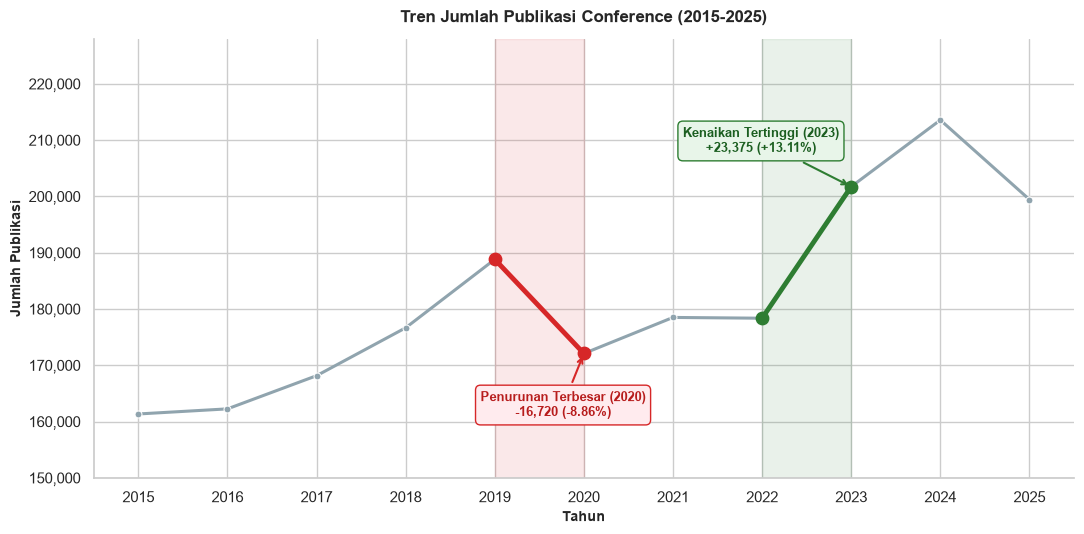

In [20]:
fig, ax = plt.subplots(figsize=(11, 5.5))

sns.lineplot(data=df_year, x="year", y="jumlah", color="#90a4ae", linewidth=2.2, marker="o", markersize=5, ax=ax)

# tandai penurunan terbesar & kenaikan tertinggi
idx_drop = df_year["selisih_persen"].idxmin()
idx_rise = df_year["selisih_persen"].idxmax()

highlight = [
    (idx_drop, "#d62728", "#b71c1c", "#ffebee", "Penurunan Terbesar", (-15, -45)),
    (idx_rise, "#2e7d32", "#1b5e20", "#e8f5e9", "Kenaikan Tertinggi", (-65, 25)),
]
for idx, color, text_color, bg, label, offset in highlight:
    seg = df_year.iloc[idx - 1 : idx + 1]
    ax.plot(seg["year"], seg["jumlah"], color=color, linewidth=3.5, zorder=4)
    ax.axvspan(seg["year"].iloc[0], seg["year"].iloc[1], color=color, alpha=0.10, zorder=1)
    ax.scatter(seg["year"], seg["jumlah"], color=color, s=80, zorder=5)

    row = df_year.loc[idx]
    ax.annotate(
        f"{label} ({int(row['year'])})\n{row['selisih']:+,.0f} ({row['selisih_persen']:+.2f}%)",
        xy=(row["year"], row["jumlah"]),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=text_color,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=bg, edgecolor=color, lw=1),
        arrowprops=dict(arrowstyle="->", color=color, lw=1.5)
    )

ax.set_xticks(df_year["year"])
ax.set_ylim(150000, 228000)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{int(y):,}"))
ax.set_title("Tren Jumlah Publikasi Conference (2015-2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah Publikasi", fontsize=10, fontweight="bold")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

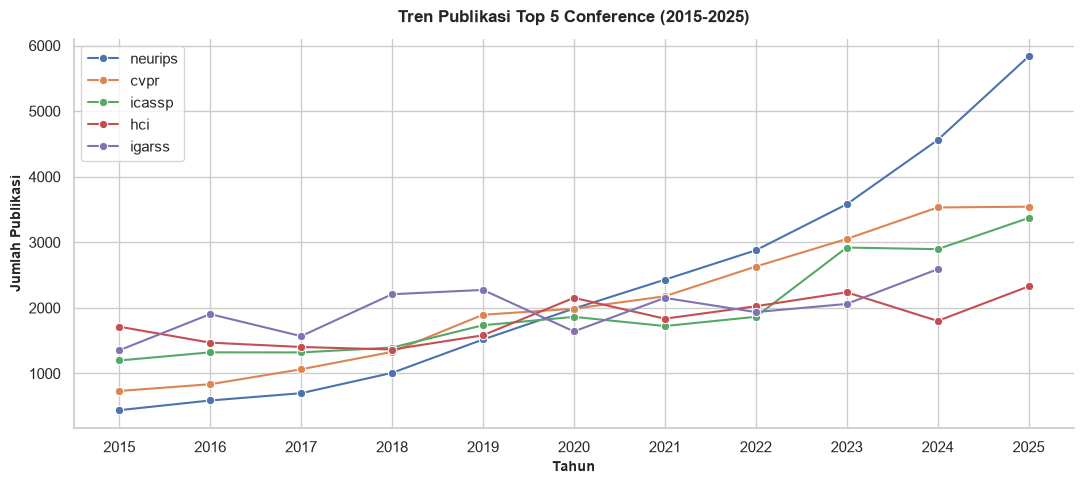

In [21]:
# tren 5 conference teratas
top5 = top10_pub['venue_normalized'].head(5)
tren_top5 = (
    df[df['venue_normalized'].isin(top5)]
      .groupby(['year', 'venue_normalized']).size()
      .reset_index(name='jumlah')
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(tren_top5, x='year', y='jumlah', hue='venue_normalized', hue_order=top5, marker='o', ax=ax)
ax.set_xticks(range(2015, 2026))
ax.set_title("Tren Publikasi Top 5 Conference (2015-2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah Publikasi", fontsize=10, fontweight="bold")
ax.legend(title='')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### 2.4 Perbandingan ranking publikasi vs author unik

In [22]:
ranking = pd.concat([pub_per_venue.rename('jumlah publikasi'), author_per_venue.rename('jumlah author')], axis=1)
ranking['rank publikasi'] = ranking['jumlah publikasi'].rank(ascending=False, method='min').astype(int)
ranking['rank author'] = ranking['jumlah author'].rank(ascending=False, method='min').astype(int)

# gabungan top 10 dari kedua ranking
gabungan = set(top10_pub['venue_normalized']) | set(top10_author['venue_normalized'])
ranking.loc[list(gabungan)].sort_values('rank publikasi')

,jumlah publikasi,jumlah author,rank publikasi,rank author
venue_normalized,,,,
neurips,25523,57823,1,1
cvpr,22776,47638,2,2
icassp,21606,42036,3,4
hci,19913,37850,4,6
igarss,19687,35213,5,8
aaai,19266,46316,6,3
emnlp,15528,35553,7,7
chi,14912,29958,8,15
embc,14677,39312,9,5


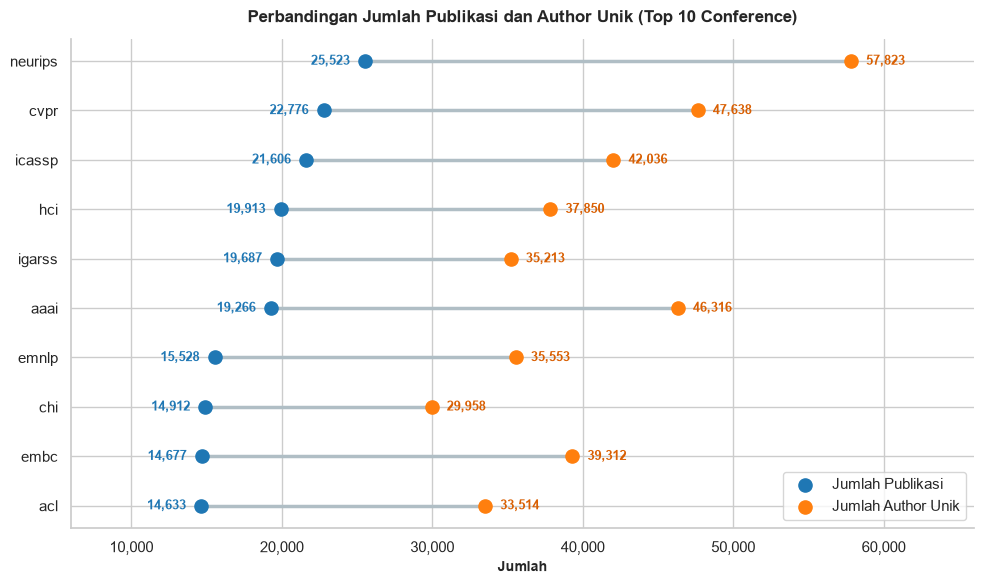

In [23]:
df_hasil = ranking.loc[top10_pub['venue_normalized']].reset_index().sort_values('jumlah publikasi')

fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(y=df_hasil["venue_normalized"], xmin=df_hasil["jumlah publikasi"], xmax=df_hasil["jumlah author"],
          color="#b0bec5", linewidth=2.5, zorder=2)
ax.scatter(df_hasil["jumlah publikasi"], df_hasil["venue_normalized"], color="#1f77b4", s=90, label="Jumlah Publikasi", zorder=3)
ax.scatter(df_hasil["jumlah author"], df_hasil["venue_normalized"], color="#ff7f0e", s=90, label="Jumlah Author Unik", zorder=3)

for _, row in df_hasil.iterrows():
    ax.text(row["jumlah publikasi"] - 1000, row["venue_normalized"], f"{row['jumlah publikasi']:,}",
            va="center", ha="right", fontsize=9, color="#1f77b4", fontweight="bold")
    ax.text(row["jumlah author"] + 1000, row["venue_normalized"], f"{row['jumlah author']:,}",
            va="center", ha="left", fontsize=9, color="#d95f02", fontweight="bold")

ax.set_xlim(6000, 66000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax.set_title("Perbandingan Jumlah Publikasi dan Author Unik (Top 10 Conference)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah", fontsize=10, fontweight="bold")
ax.set_ylabel("")
ax.legend(loc="lower right", frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### 2.5 Jawaban

**Conference mana yang paling populer berdasarkan jumlah publikasi?**

NeurIPS, dengan 25.523 publikasi selama 2015-2025, disusul CVPR (22.776) dan ICASSP (21.606). Publikasi NeurIPS per tahun naik terus, dari 440 di 2015 jadi 5.833 di 2025, sejalan dengan berkembangnya riset machine learning.

**Apakah conference dengan publikasi terbanyak juga punya author unik terbanyak?**

Tidak selalu. Peringkat 1-2 sama (NeurIPS, CVPR), tapi setelah itu urutannya bergeser:
- AAAI peringkat 6 di publikasi tapi peringkat 3 di author unik. EMBC naik dari 9 ke 5.
- HCI (4 -> 6) dan IGARSS (5 -> 8) turun. Paper-nya banyak tapi author-nya relatif sedikit, artinya banyak author yang publish berulang di sana.
- ICCV masuk top 10 author unik walaupun tidak masuk top 10 publikasi, sedangkan CHI sebaliknya.

**Bagaimana perubahan aktivitas publikasi selama periode pengamatan?**

Secara umum naik, dari 161.353 publikasi di 2015 jadi 213.570 di 2024 (sekitar +32%).
- Penurunan terbesar di 2020 (-16.720 atau -8,9%), kemungkinan karena pandemi COVID-19 (banyak conference dibatalkan atau pindah online).
- Kenaikan terbesar di 2023 (+23.375 atau +13,1%), sejalan dengan ledakan riset AI.
- 2025 turun 6,6%, tapi kemungkinan besar karena data 2025 di DBLP belum lengkap (lihat keterbatasan data), bukan penurunan yang sebenarnya.

## Task 3 - Transactional Database Construction

In [24]:
# format long: 1 baris = 1 (author, venue, year) dari 1 paper
long_df = (
    df[['authors_normalized', 'venue_normalized', 'year']]
      .explode('authors_normalized')
      .rename(columns={'authors_normalized': 'author', 'venue_normalized': 'venue'})
      .dropna(subset=['author'])
)
print("Baris long:", f"{len(long_df):,}")
long_df.head()

Baris long: 7,881,218


,author,venue,year
11,carina corbin,iwsds,2015
11,fabrizio morbini,iwsds,2015
11,david r. traum,iwsds,2015
17,luis fernando d'haro,iwsds,2015
17,seokhwan kim,iwsds,2015


### 3.1 Membentuk transactional database

Item dalam transaksi dibuat unik (himpunan), jadi author yang publish 5 paper di CVPR tetap dihitung 1 item `cvpr`.

In [25]:
# A. author-based: 1 transaksi = 1 author
a_pairs = long_df[['author', 'venue']].drop_duplicates()

tx_author = (
    a_pairs.groupby('author')['venue']
           .apply(lambda s: sorted(s))
           .rename('items')
           .reset_index()
)
tx_author['n_items'] = tx_author['items'].str.len()

In [26]:
# B. author-year-based: 1 transaksi = 1 author di 1 tahun
ay_pairs = long_df[['author', 'year', 'venue']].drop_duplicates()

tx_author_year = (
    ay_pairs.groupby(['author', 'year'])['venue']
            .apply(lambda s: sorted(s))
            .rename('items')
            .reset_index()
)
tx_author_year['n_items'] = tx_author_year['items'].str.len()

### 3.2 Contoh transaksi

In [27]:
print("=== Author-Based: 10 acak ===")
display(tx_author.sample(10, random_state=42))

print("=== Author-Based: 10 dengan item >= 3 ===")
display(tx_author[tx_author['n_items'] >= 3].sample(10, random_state=42))

print("=== Author-Year: 10 acak ===")
display(tx_author_year.sample(10, random_state=42))

print("=== Author-Year: 10 dengan item >= 2 ===")
display(tx_author_year[tx_author_year['n_items'] >= 2].sample(10, random_state=42))

=== Author-Based: 10 acak ===


,author,items,n_items
1225536,pierre kleberger,"[dsn, dsn-w, prdc, vnc]",4
671308,javad tayefi,[iwcit],1
754071,joshua c. zhao 0001,"[cvpr, dsn-s, sp]",3
104795,andrew dillon,[asist],1
764477,juan f. valencia,[hci],1
1667031,xin (robert) luo,"[amcis, hicss, icec, pacis]",4
1331485,ruotian lu,[icc],1
1583608,vadim levin,[vlsi technology and circuits],1
1111386,naghmeh bandari,[embc],1
1384689,sebastian stutz,[isgt europe],1


=== Author-Based: 10 dengan item >= 3 ===


,author,items,n_items
744770,joo seong jeong,"[eurosys, hotos, icdcs, mobisys, nsdi, osdi]",6
1385961,sefa kayraklik,"[blackseacom, icc, siu, softcom, vtc2023-sprin...",6
1751442,yuelu wang,"[csai, dsde, icbdt]",3
803629,karim ben alaya,"[icmv, idaacs, iwssip]",3
403742,elie cattan,"[aime, chi, icsm, iss, its]",5
344430,davide fissore,"[i2mtc, ictai, ppdp]",3
959539,marcia pasin,"[ant/edi40, cec, compsac, iccp, iceis, icinco,...",14
1009263,matthew p. bowers,"[arso, biodevices, biostec, icra]",4
401009,elena kuss,"[emisa, er, er forum/demos, iswc, otm conferen...",5
1090268,moritz bärthel,"[acssc, asap, conga, eusipco, ieeeconf, iscas,...",9


=== Author-Year: 10 acak ===


,author,year,items,n_items
1414668,ivan bogatyy,2015,[websci],1
805352,dirk inzé,2021,[rovisp],1
567644,chi-kiu lo,2019,"[conll, wmt]",2
3535486,vijaynagtangirala,2023,[ibica],1
1959596,levent tolga eren,2018,[aist],1
1669269,josef tkadlec,2023,[ecai],1
2455458,mónica de la roca,2023,[fie],1
811548,dmitry petrov,2020,"[icin, icumt, ieee sensors]",3
378075,bart a. j. m. wagemans,2023,[miccai],1
1978705,lijie deng,2017,[miccai],1


=== Author-Year: 10 dengan item >= 2 ===


,author,year,items,n_items
3364504,tatsuya kawahara,2017,"[apsipa, asru, icaart, icassp, ijcnlp, intersp...",10
449848,bowen tian,2016,"[ipccc, nas]",2
970358,faran ahmad,2019,"[ijcai, wacv]",2
1840822,kevin doherty,2021,"[chi, cui]",2
507644,catalin visan,2023,"[islped, sped]",2
2939718,ruikun zhou,2025,"[acc, cdc, l4dc]",3
3291952,sungchul kang,2016,"[icra, iros]",2
313694,arnavi chheda-kothary,2025,"[acl, assets, chi, iui]",4
2367125,mingxuan zhao,2025,"[aaai, iclr]",2
2911831,roman mazurenko,2025,"[itpm, stiot]",2


### 3.3 Jumlah transaksi

In [28]:
print("Jumlah transaksi Author-Based     :", f"{len(tx_author):,}")
print("Jumlah transaksi Author-Year-Based:", f"{len(tx_author_year):,}")

Jumlah transaksi Author-Based     : 1,819,240
Jumlah transaksi Author-Year-Based: 4,086,070


### 3.4 Item unik dan distribusi jumlah item per transaksi


===== Author-Based =====
Jumlah transaksi      : 1819240
Jumlah item unik      : 4478
Total item (isi tx)   : 4894913
count    1819240.00
mean           2.69
std            4.50
min            1.00
50%            1.00
75%            3.00
90%            6.00
95%            9.00
99%           21.00
max          339.00
Name: n_items, dtype: float64
Transaksi 1 item      : 58.18%
Transaksi >= 2 item   : 41.82%



===== Author-Year-Based =====
Jumlah transaksi      : 4086070
Jumlah item unik      : 4478
Total item (isi tx)   : 6505522
count    4086070.00
mean           1.59
std            1.40
min            1.00
50%            1.00
75%            2.00
90%            3.00
95%            4.00
99%            7.00
max           85.00
Name: n_items, dtype: float64
Transaksi 1 item      : 70.96%
Transaksi >= 2 item   : 29.04%


,Author-Based,Author-Year
n_items,,
1,1058446,2899637
2,291883,662804
3,140870,253969
4,84114,117217
5,55548,60942
6,38645,33996
7,28583,19892
8,21234,12491
9,16392,7621


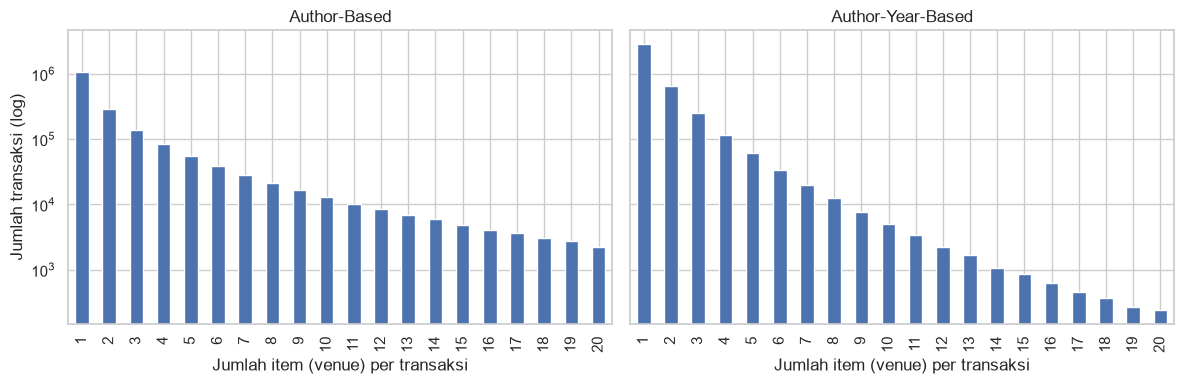

In [29]:
def summarize(tx, name):
    all_items = set(i for items in tx['items'] for i in items)
    n = tx['n_items']
    print(f"\n===== {name} =====")
    print("Jumlah transaksi      :", len(tx))
    print("Jumlah item unik      :", len(all_items))
    print("Total item (isi tx)   :", n.sum())
    print(n.describe(percentiles=[.5, .75, .9, .95, .99]).round(2))
    print("Transaksi 1 item      : %.2f%%" % ((n == 1).mean() * 100))
    print("Transaksi >= 2 item   : %.2f%%" % ((n >= 2).mean() * 100))
    return all_items


items_A = summarize(tx_author, "Author-Based")
items_AY = summarize(tx_author_year, "Author-Year-Based")

# distribusi (tabel)
dist_A = tx_author['n_items'].value_counts().sort_index()
dist_AY = tx_author_year['n_items'].value_counts().sort_index()
display(pd.DataFrame({'Author-Based': dist_A, 'Author-Year': dist_AY}).fillna(0).astype(int).head(15))

# distribusi (grafik, skala log karena sangat skewed)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, d, t in zip(ax, [dist_A, dist_AY], ['Author-Based', 'Author-Year-Based']):
    d.head(20).plot(kind='bar', ax=a)
    a.set_yscale('log')
    a.set_title(t)
    a.set_xlabel('Jumlah item (venue) per transaksi')
    a.set_ylabel('Jumlah transaksi (log)')
plt.tight_layout()
plt.show()

### 3.5 Perbedaan kedua representasi

Author-based punya 1.819.240 transaksi, author-year 4.086.070. Item unik-nya sama (4.478), tapi rata-rata item per transaksi 2,69 vs 1,59, transaksi yang cuma 1 item 58,2% vs 71,0%, dan item terbanyak dalam 1 transaksi 339 vs 85.

- Author-year punya 2,2x lebih banyak transaksi karena satu author dipecah per tahun aktif (rata-rata 2,25 tahun per author).
- Item unik sama, karena isinya sama-sama daftar conference. Yang beda hanya cara pengelompokannya.
- Transaksi author-year lebih pendek dan lebih banyak yang cuma berisi 1 item, jadi lebih sparse.
- Author-based menangkap pola "pernah publish di X dan Y" walaupun beda tahun. Author-year hanya menangkap conference yang dipakai di tahun yang sama.

### 3.6 Kelebihan dan keterbatasan untuk Frequent Pattern Mining

**Author-based**
- Kelebihan: transaksi lebih padat, jadi itemset ukuran >= 2 lebih banyak dan pola lebih mudah ditemukan. Support-nya mudah dibaca, yaitu persentase author yang pernah publish di X dan Y.
- Keterbatasan: tidak ada konteks waktu. Author yang aktif lama atau sangat produktif punya transaksi sangat panjang (sampai 339 item), sehingga jumlah kombinasi itemset membengkak dan bisa muncul asosiasi semu.

**Author-year-based**
- Kelebihan: asosiasinya lebih relevan secara waktu karena conference-nya dipakai di tahun yang sama, dan bisa dipecah per periode untuk melihat tren.
- Keterbatasan: sangat sparse (71% transaksi cuma 1 item dan tidak berguna untuk rule), jadi min support harus lebih kecil. Author yang aktif lama dihitung berkali-kali. Conference dua tahunan seperti ICCV (tahun ganjil) dan ECCV (tahun genap) juga tidak mungkin muncul di transaksi yang sama.

### Simpan transaksi

In [30]:
# dipakai di 02_modeling.ipynb
os.makedirs(PROCESSED_DIR, exist_ok=True)

tx_author.to_pickle(f'{PROCESSED_DIR}/tx_author.pkl')
tx_author_year.to_pickle(f'{PROCESSED_DIR}/tx_author_year.pkl')